In [1]:
import geopandas as gpd
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt
import matplotlib as mpl

In [14]:
gdf_data = gpd.read_file(r"D:\Profiles\Tim\Documents\Community Response\tdh-community-response\GPR\Prepared data for regression\Kintore-Tealing-DZ22-X_Y.geojson")
gdf_data = gdf_data.set_index("outputAreaCode")

In [17]:
gdf_OA_data = gpd.read_file(r"D:\Profiles\Tim\Documents\Community Response\Codebase\validation\temporary_gdf.geojson")
gdf_OA_data = gdf_OA_data.set_index("2021 output area")

In [18]:
pivot = pd.pivot_table(gdf_OA_data, values = "total_route_exposure", index = "aggregation_small", aggfunc = "sum")

gdf_data["total_route_exposure"] = pivot["total_route_exposure"]

del gdf_OA_data

In [19]:
gdf_data

,pop_total,area_sqkm,density_pop/sqkm,distance_to_route,DZ22_Name,IZ22_Name,LA_Name,UR22_8FOLD_MIN,p_children,mean_adult_age,...,p_religion,p_nonchristian_religion,p_owned,p_car_drive_commute,cumulativeActivity,modelled_per_100,empirical,empirical_per_100,geometry,total_route_exposure
outputAreaCode,,,,,,,,,,,,,,,,,,,,,
S01013482,973,4.411924,220.538710,3504.062956,Culter - 01,Culter,Aberdeen City,1,0.184346,51.323232,...,0.400419,0.014675,0.717119,0.509514,0.852964,0.087663,0.0,0.0,"POLYGON ((384315 799988.6, 384315.001 799988.5...",0.433202
S01013483,760,0.364950,2082.474261,5579.078287,Culter - 02,Culter,Aberdeen City,1,0.169960,55.484127,...,0.442408,0.036649,0.740741,0.535826,0.436432,0.057425,0.0,0.0,"POLYGON ((384041 801195, 384001.175 801204.19,...",0.296829
S01013484,542,0.255700,2119.672902,5758.693477,Culter - 03,Culter,Aberdeen City,1,0.205556,47.086247,...,0.371115,0.029250,0.751381,0.593443,0.273621,0.050484,0.0,0.0,"POLYGON ((383561.069 800583.839, 383573.899 80...",0.224403
S01013485,561,0.096254,5828.313590,6405.758335,Culter - 04,Culter,Aberdeen City,1,0.229706,51.515695,...,0.400362,0.052536,0.741071,0.541176,0.232201,0.041391,0.0,0.0,"POLYGON ((383872.071 800723.988, 383852.082 80...",0.156567
S01013486,618,0.180077,3431.873321,6590.597866,Culter - 05,Culter,Aberdeen City,1,0.204800,55.655936,...,0.423263,0.022617,0.676370,0.569343,0.201544,0.032612,0.0,0.0,"POLYGON ((384126.04 800561.993, 384126.04 8005...",0.132590
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
S01019261,703,1.988475,353.537336,8480.227004,"Invergowrie, Longforgan and Abernyte - 02","Invergowrie, Longforgan and Abernyte",Perth and Kinross,6,0.194940,58.650647,...,0.565280,0.012912,0.879944,0.602740,0.020390,0.002900,0.0,0.0,"MULTIPOLYGON (((333052 730502, 333067.264 7305...",0.000393
S01019262,1231,1.892279,650.538440,8790.299414,"Invergowrie, Longforgan and Abernyte - 03","Invergowrie, Longforgan and Abernyte",Perth and Kinross,6,0.170752,54.712315,...,0.513799,0.015422,0.796099,0.542190,0.000000,0.000000,0.0,0.0,"MULTIPOLYGON (((329488.502 733539.896, 329511....",0.000486
S01019263,977,0.660595,1478.969028,8163.271403,"Invergowrie, Longforgan and Abernyte - 04","Invergowrie, Longforgan and Abernyte",Perth and Kinross,1,0.207216,51.330299,...,0.475460,0.028630,0.738509,0.504854,0.253780,0.025975,0.0,0.0,"POLYGON ((335195.898 730151.796, 335209.701 73...",0.038438


In [20]:
cols = ["p_children", "mean_adult_age", "p_level_4", "p_green_heating", "p_married", "p_born_in_UK", "p_L1_to_L6", "p_religion", "p_nonchristian_religion", "p_owned", "p_car_drive_commute", "total_route_exposure"]

gdf_data_reduced = gdf_data.loc[:,cols + ["empirical", "geometry"]]
# For exclusion of Dundee City:
# gdf_data_reduced = gdf_data.loc[~(gdf_data["council"] == "S12000042"),cols + ["empirical", "geometry"]]

In [21]:
X = np.array(gdf_data_reduced.loc[:,cols].fillna(0.0))
# y = 1 * x_0 + 2 * x_1 + 3
y = np.array(gdf_data_reduced.loc[:,"empirical"])
reg = LinearRegression().fit(X, y)
reg.score(X, y)

# reg.coef_
# array([1., 2.])
# reg.intercept_
# np.float64(3.0)
# reg.predict(np.array([[3, 5]]))

0.43035757939013675

In [22]:
dict(zip(gdf_data_reduced.iloc[:,:-1].columns,reg.coef_))

{'p_children': np.float64(-0.6497118436660198),
 'mean_adult_age': np.float64(0.04275784302433427),
 'p_level_4': np.float64(5.191547531431901),
 'p_green_heating': np.float64(-4.426665863729711),
 'p_married': np.float64(1.1726738562564227),
 'p_born_in_UK': np.float64(-0.5815674202806144),
 'p_L1_to_L6': np.float64(-4.20625207919573),
 'p_religion': np.float64(-0.3336478502369107),
 'p_nonchristian_religion': np.float64(-3.163168349049944),
 'p_owned': np.float64(-1.0692279542367322),
 'p_car_drive_commute': np.float64(0.8476033125919302),
 'total_route_exposure': np.float64(0.15474015769556665)}

In [23]:
gdf_data_reduced["predicted"] = reg.predict(X)

In [25]:
(gdf_data_reduced.loc[:,["predicted", "empirical"]].corr().iloc[0,1],
 gdf_data_reduced.loc[:,["predicted", "empirical"]].corr(method = "spearman").iloc[0,1])

(np.float64(0.6560164474997083), np.float64(0.35228491354794084))

[]

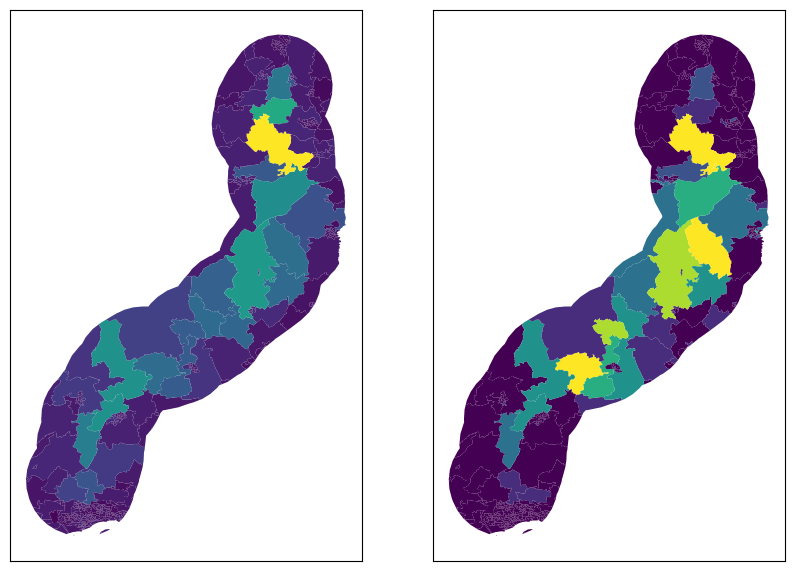

In [26]:
fig, ax = plt.subplots(figsize = (10,10), ncols = 2)
norm = mpl.colors.Normalize(vmin=0, vmax=8)
gdf_data_reduced.plot(column = "predicted", ax = ax[0])
gdf_data_reduced.plot(column = "empirical", ax = ax[1], norm = norm)
ax[0].set_xticks([])
ax[0].set_yticks([])
ax[1].set_xticks([])
ax[1].set_yticks([])

In [52]:
gdf_data_reduced = gdf_data_reduced.sort_values("predicted", ascending = False).iloc[:200, :]
gdf_data_reduced

,p_children,mean_adult_age,p_level_4,p_green_heating,p_married,p_born_in_UK,p_L1_to_L6,p_religion,p_nonchristian_religion,p_owned,p_car_drive_commute,total_route_exposure,empirical,geometry,predicted
182,0.343750,44.342857,0.584746,0.000000,0.745342,0.896970,0.486957,0.441718,0.012270,0.721212,0.523256,23.252197,3.0,"MULTIPOLYGON (((375434 807070, 375326 807103, ...",3.622080
186,0.321429,49.605263,0.488095,0.054348,0.585903,0.925439,0.482955,0.442553,0.004255,0.574561,0.627451,22.992053,0.0,"MULTIPOLYGON (((373593 809806, 373543 809605, ...",3.419349
79,0.265000,51.782313,0.477419,0.033708,0.578947,0.932367,0.558282,0.391960,0.005025,0.898058,0.594059,18.341526,4.0,"MULTIPOLYGON (((378782.574 796779.229, 378707....",2.664282
178,0.306977,51.731544,0.614379,0.090909,0.744186,0.953488,0.490066,0.421296,0.009259,0.855814,0.560000,16.272727,8.0,"MULTIPOLYGON (((377027 802241, 376451 802176, ...",2.585959
1914,0.271523,51.600000,0.406504,0.000000,0.500000,0.980645,0.309735,0.386076,0.000000,0.737179,0.623529,16.619501,1.0,"MULTIPOLYGON (((363787.001 770971, 363790.585 ...",2.577788
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2085,0.277228,51.328767,0.457831,0.000000,0.695238,0.910891,0.536585,0.460784,0.029412,0.961538,0.518519,1.446714,1.0,"MULTIPOLYGON (((378576.933 780983.656, 378576....",0.213418
927,0.158273,54.461538,0.345133,0.000000,0.546154,0.960938,0.285714,0.592000,0.000000,0.776000,0.621212,0.185629,0.0,"MULTIPOLYGON (((336953.001 753000, 337000 7530...",0.212424
220,0.193548,56.830000,0.500000,0.089552,0.511811,0.930233,0.515152,0.528926,0.000000,0.905512,0.508475,0.934953,0.0,"MULTIPOLYGON (((372231 815966, 372201 815986.9...",0.212276
2147,0.227273,52.445378,0.570175,0.018519,0.695035,0.875862,0.525424,0.375000,0.000000,0.896552,0.507692,0.175572,0.0,"MULTIPOLYGON (((383385 800703, 383373.373 8007...",0.210951
